In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.preprocessing import StandardScaler
import umap

# ==========================================
# 0. Path Definitions & Style
# ==========================================
BASE_DIR = Path('/kyb/agpd/wwang/data/')
OUT_DIR = Path('/kyb/agpd/wwang/sst-pomdp/outputs/')

# LaTeX Display Names for Plots
PARAM_DISPLAY_NAMES = {
    'q_d_n': r"$\chi'$",
    'q_d': r"$\chi$",
    'q_s_n': r"$\sigma'$",
    'q_s': r"$\sigma$",
    'cost_stop_error': r"$c_{\mathrm{se}}$",
    'cost_time': r"$c_t$",
}

Running Version 1: Raw Embedding UMAP...


/kyb/agpd/wwang/tst/testenv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


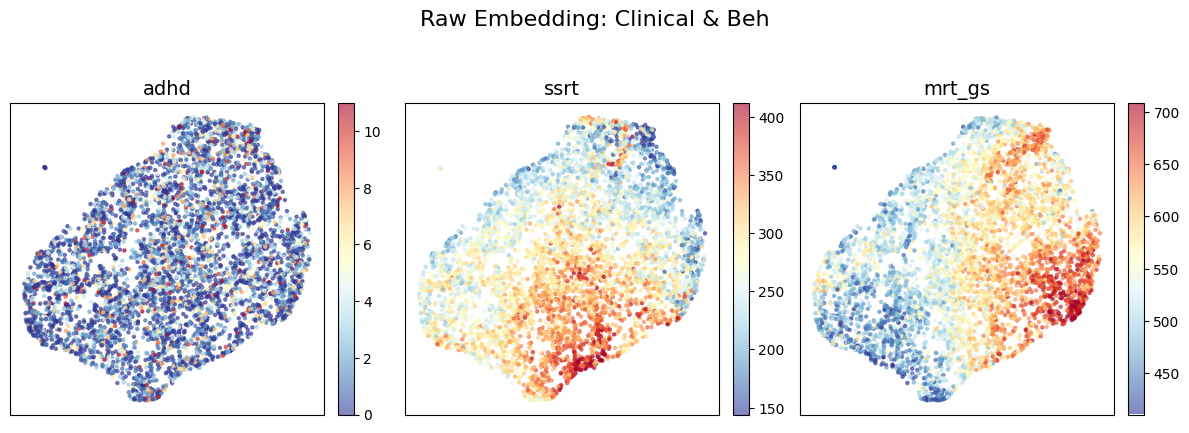

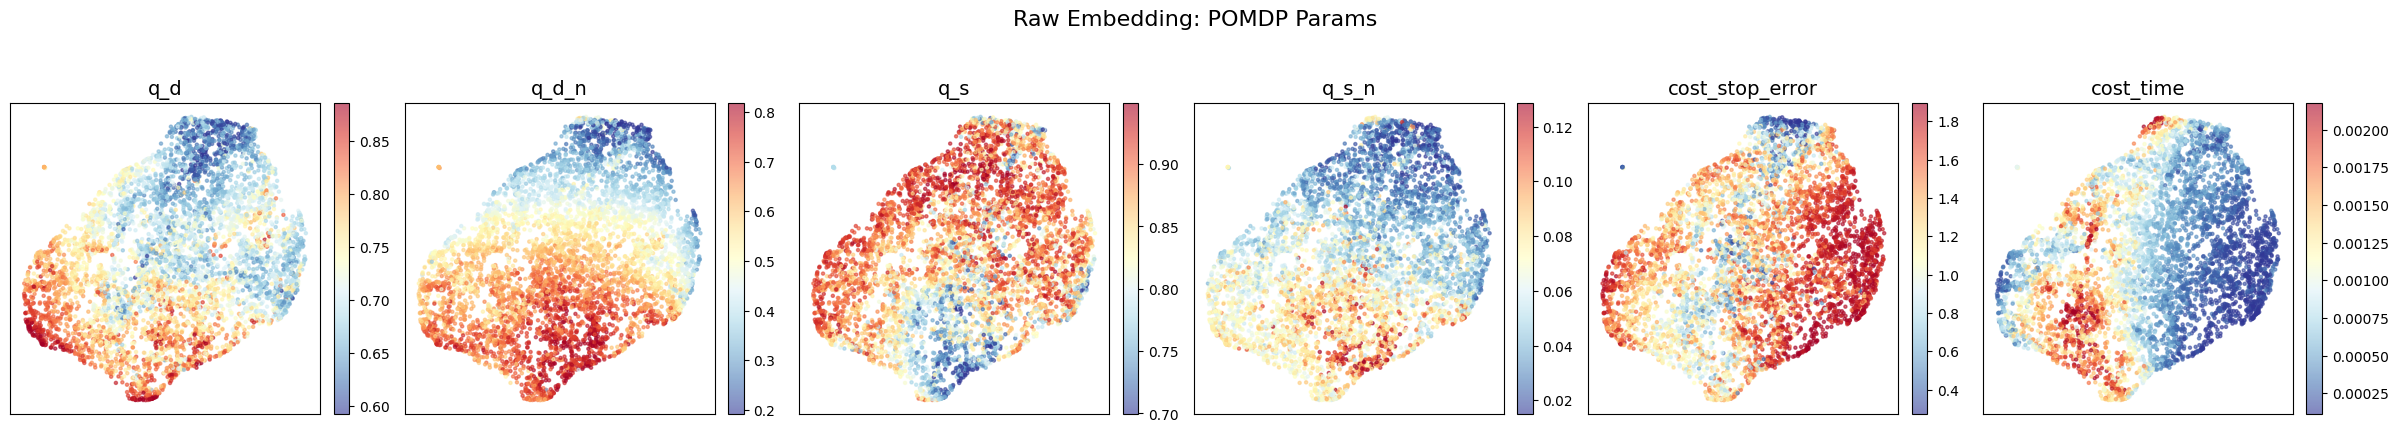

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cross_decomposition import CCA
import umap

# ==========================================
# 1. 数据加载与对齐
# ==========================================
def prepare_data():
    df_emb = pd.read_csv(OUT_DIR / 'embeddings.csv')
    df_stats = pd.read_csv(OUT_DIR / 'stats_beh_full.csv')
    df_post = pd.read_csv(OUT_DIR / 'posterior_summary.csv')

    # 统一格式并 Pivot 参数表
    df_post['year'] = df_post['subject_year'].astype(str)
    df_post_pivot = df_post.pivot_table(index=['subject_id', 'year'], 
                                        columns='param', values='mean').reset_index()
    
    df_emb['year'] = df_emb['year'].astype(str)
    df_stats['year'] = df_stats['year'].astype(str)
    
    # 合并
    df = pd.merge(df_emb, df_stats, on=['subject_id', 'year', 'filename'])
    df = pd.merge(df, df_post_pivot, on=['subject_id', 'year'])
    
    # 定义列名
    emb_cols = [c for c in df.columns if c.startswith('emb_')]
    param_cols = ['q_d', 'q_d_n', 'q_s', 'q_s_n', 'cost_stop_error', 'cost_time']
    clinical_cols = ['adhd', 'ssrt', 'mrt_gs']
    
    df_clean = df.dropna(subset=emb_cols + param_cols + clinical_cols).copy()
    return df_clean, emb_cols, param_cols, clinical_cols

df_final, emb_cols, param_cols, clinical_cols = prepare_data()

# ==========================================
# 绘图辅助函数 (直接使用原始变量名)
# ==========================================
def plot_grid(df, x_col, y_col, targets, title, filename):
    n = len(targets)
    fig, axes = plt.subplots(1, n, figsize=(4*n, 4))
    for i, var in enumerate(targets):
        vmin, vmax = df[var].quantile([0.01, 0.99])
        sc = axes[i].scatter(df[x_col], df[y_col], c=df[var], 
                             s=5, alpha=0.6, cmap='RdYlBu_r', vmin=vmin, vmax=vmax)
        axes[i].set_title(var, fontsize=14)
        axes[i].set_xticks([]); axes[i].set_yticks([])
        plt.colorbar(sc, ax=axes[i], fraction=0.046, pad=0.04)
    plt.suptitle(title, y=1.05, fontsize=16)
    plt.tight_layout()
    plt.savefig(f"{filename}.png", dpi=300, bbox_inches='tight')
    plt.show()

# ==========================================
# VERSION 1: Raw Embedding UMAP (不使用 CCA)
# ==========================================
print("Running Version 1: Raw Embedding UMAP...")
X_raw = StandardScaler().fit_transform(df_final[emb_cols])
reducer_raw = umap.UMAP(n_neighbors=30, min_dist=0.1, random_state=42)
u_raw = reducer_raw.fit_transform(X_raw)

df_final['raw_u1'] = u_raw[:, 0]
df_final['raw_u2'] = u_raw[:, 1]

# 看看临床指标
plot_grid(df_final, 'raw_u1', 'raw_u2', ['adhd', 'ssrt', 'mrt_gs'], 
          "Raw Embedding: Clinical & Beh", "v1_raw_clinical")
# 看看六个参数
plot_grid(df_final, 'raw_u1', 'raw_u2', param_cols, 
          "Raw Embedding: POMDP Params", "v1_raw_params")
